<a href="https://colab.research.google.com/github/themdanas/Deep_Generative_Models/blob/main/VAE_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torchvision matplotlib -q

In [ ]:
import torch.nn
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision import transforms

import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [ ]:
#Loading the MNIST dataset
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

batch_size = 128

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 369kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.11MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.26MB/s]

Train samples: 60000
Test samples: 10000


In [ ]:
class VAE(nn.Module):
  def __init__(self, latent_dim=2):
    super().__init__()
    self.latent_dim = latent_dim

  #encoder
    self.encoder = nn.Sequential(
      nn.Flatten(),
      nn.Linear(28*28, 400),
      nn.ReLU(),
    )

    self.fc_mu = nn.Linear(400, latent_dim)
    self.fc_logvar = nn.Linear(400, latent_dim)

    self.decoder = nn.Sequential(
        nn.Linear(latent_dim, 400),
        nn.ReLU(),
        nn.Linear(400, 28*28),
        nn.Sigmoid()

       )

  def encode(self,x):
      h = self.encoder(x)
      mu = self.fc_mu(h)
      logvar = self.fc_logvar(h)
      return mu, logvar

  def reparameterize(self, mu, logvar):
      std = torch.exp(0.5 * logvar)
      eps = torch.randn_like(std)
      return mu + eps * std

  def decode(self,z):
      x_hat = self.decoder(z)
      return x_hat.view(-1, 1, 28, 28)

  def forward(self, x):
      mu, logvar = self.encode(x)
      z = self.reparameterize(mu, logvar)
      x_hat = self.decode(z)
      return x_hat, mu, logvar

In [ ]:
#instantiate the model
latent_dim = 2
model = VAE(latent_dim=latent_dim).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
# ELBO Loss = Recon Loss + KL divergence
def loss_function(x_hat, x, mu, logvar):

  x = x.view(x.size(0),-1)
  x_hat = x_hat.view(x_hat.size(0),-1)

  #recontruction loss
  recon_loss = F.binary_cross_entropy(x_hat, x, reduction='sum')

  #KL divergence
  kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

  return recon_loss + kl_loss , recon_loss, kl_loss


In [ ]:
from torch import kl_div
# Training + test Loops

def train_epoch(epoch):
  model.train()
  total_loss = total_recon = total_kl =0

  for x, _ in train_loader:
    x = x.to(device)
    optimizer.zero_grad()

    x_hat, mu, logvar = model(x)
    loss, recon, kl = loss_function(x_hat, x, mu, logvar)

    loss.backward()
    optimizer.step()

    total_loss += loss.item()
    total_recon += recon.item()
    total_kl += kl.item()

  n = len(train_dataset)
  print(f"Epoch {epoch:02d} | Loss {total_loss/n:.4f} | Recon {total_recon/n:.4f} | KL {total_kl/n:.4f}")


def test_epoch():
  model.eval()
  total_loss = total_recon = total_kl =0

  with torch.no_grad():
    for x, _ in test_loader:
      x = x.to(device)
      x_hat, mu, logvar = model(x)
      loss, recon, kl = loss_function(x_hat, x, mu, logvar)

      total_loss += loss.item()
      total_recon += recon.item()
      total_kl += kl.item()

  n = len(test_dataset)
  print(f"[Test] Loss {total_loss/n:.4f} | Recon {total_recon/n:.4f} | KL {total_kl/n:.4f}")





In [ ]:
num_epochs = 10
for epoch in range(1, num_epochs+1):
  train_epoch(epoch)
  test_epoch()

Epoch 01 | Loss 167.3012 | Recon 162.0551 | KL 5.2461
[Test] Loss 164.7391 | Recon 159.4349 | KL 5.3042
Epoch 02 | Loss 163.7860 | Recon 158.4797 | KL 5.3062
[Test] Loss 162.3945 | Recon 157.2868 | KL 5.1076
Epoch 03 | Loss 161.6963 | Recon 156.3426 | KL 5.3537
[Test] Loss 160.4749 | Recon 155.1387 | KL 5.3362
Epoch 04 | Loss 160.0787 | Recon 154.6186 | KL 5.4601
[Test] Loss 159.2238 | Recon 153.9420 | KL 5.2818
Epoch 05 | Loss 158.6854 | Recon 153.1353 | KL 5.5501
[Test] Loss 157.6017 | Recon 152.1289 | KL 5.4728
Epoch 06 | Loss 157.5004 | Recon 151.8960 | KL 5.6044
[Test] Loss 156.9686 | Recon 151.2438 | KL 5.7249
Epoch 07 | Loss 156.5513 | Recon 150.8531 | KL 5.6983
[Test] Loss 156.1032 | Recon 150.5530 | KL 5.5502
Epoch 08 | Loss 155.6881 | Recon 149.9479 | KL 5.7402
[Test] Loss 155.3227 | Recon 149.6453 | KL 5.6774
Epoch 09 | Loss 154.9462 | Recon 149.1386 | KL 5.8076
[Test] Loss 155.0659 | Recon 149.2307 | KL 5.8353
Epoch 10 | Loss 154.2397 | Recon 148.3982 | KL 5.8416
[Test] Los

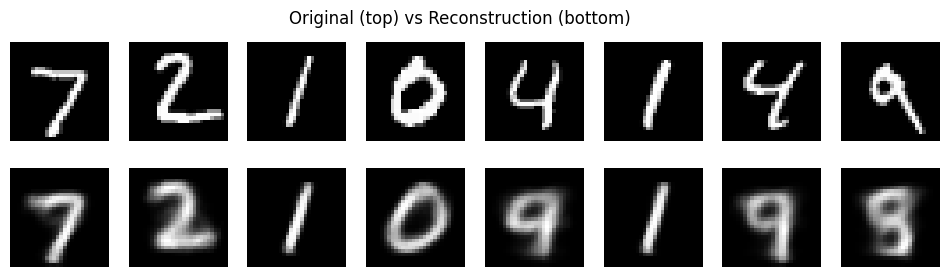

In [ ]:
# visulize recontructions
def show_reconstructions():
    model.eval()
    x, _ = next(iter(test_loader))
    x = x.to(device)

    with torch.no_grad():
        x_hat, _, _ = model(x)

    x = x.cpu().numpy()
    x_hat = x_hat.cpu().numpy()

    n = 8
    plt.figure(figsize=(12, 3))

    for i in range(n):
        plt.subplot(2, n, i+1)
        plt.imshow(x[i][0], cmap="gray")
        plt.axis("off")

        plt.subplot(2, n, n+i+1)
        plt.imshow(x_hat[i][0], cmap="gray")
        plt.axis("off")

    plt.suptitle("Original (top) vs Reconstruction (bottom)")
    plt.show()

show_reconstructions()


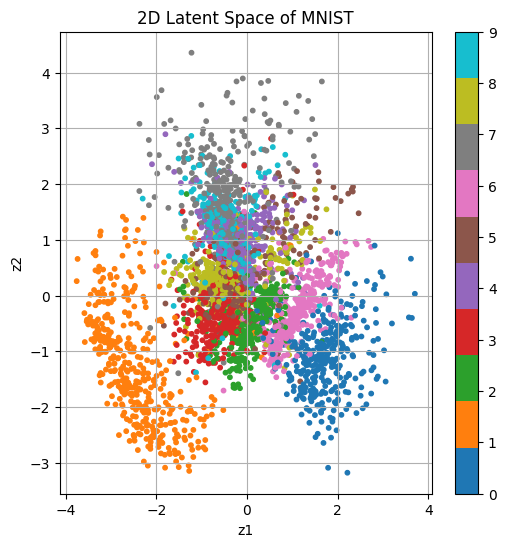

In [ ]:
# ploting 2d latent space
def plot_latent_space(num_batches=30):
    model.eval()
    zs, labels = [], []

    with torch.no_grad():
        for i, (x, y) in enumerate(test_loader):
            if i >= num_batches:
                break
            x = x.to(device)
            mu, _ = model.encode(x)
            zs.append(mu.cpu().numpy())
            labels.append(y.numpy())

    zs = np.concatenate(zs, axis=0)
    labels = np.concatenate(labels, axis=0)

    plt.figure(figsize=(6, 6))
    scatter = plt.scatter(zs[:, 0], zs[:, 1], c=labels, cmap="tab10", s=10)
    plt.colorbar(scatter)
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.title("2D Latent Space of MNIST")
    plt.grid(True)
    plt.show()

plot_latent_space()


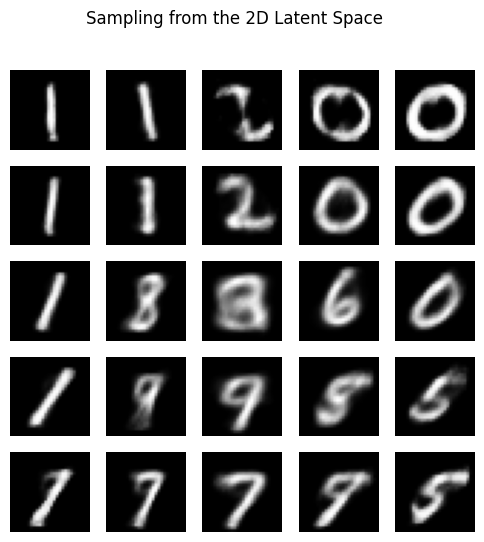

In [ ]:
# sample latent grid
def sample_latent_grid():
    model.eval()
    n = 5
    grid_x = np.linspace(-3, 3, n)
    grid_y = np.linspace(-3, 3, n)

    plt.figure(figsize=(6, 6))

    with torch.no_grad():
        for i, y in enumerate(grid_y):
            for j, x in enumerate(grid_x):
                z = torch.tensor([[x, y]], dtype=torch.float32).to(device)
                x_hat = model.decode(z)[0, 0].cpu().numpy()
                plt.subplot(n, n, i*n + j + 1)
                plt.imshow(x_hat, cmap="gray")
                plt.axis("off")

    plt.suptitle("Sampling from the 2D Latent Space")
    plt.show()

sample_latent_grid()


In [ ]:
# latent samples per epoch
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, pi, exp

def collect_latent_samples(model, data_loader, num_batches=50, use_mu=True):
    """
    Go through a few batches and collect latent vectors z (or mu).
    - use_mu=True: use the mean μ(x) of q(z|x)
    - use_mu=False: sample z via reparameterization
    """
    model.eval()
    zs = []

    with torch.no_grad():
        for i, (x, _) in enumerate(data_loader):
            if i >= num_batches:
                break
            x = x.to(device)
            mu, logvar = model.encode(x)
            if use_mu:
                z = mu
            else:
                # sample z = mu + sigma * eps
                std = torch.exp(0.5 * logvar)
                eps = torch.randn_like(std)
                z = mu + std * eps
            zs.append(z.cpu().numpy())

    if len(zs) == 0:
        return None

    zs = np.concatenate(zs, axis=0)   # shape [N, latent_dim]
    return zs


In [ ]:
#plot latent distribution vs gaussian
def normal_pdf(x):
    # PDF of N(0,1)
    return (1.0 / sqrt(2 * pi)) * np.exp(-0.5 * x**2)

def plot_latent_hist(z_samples, epoch, bins=40):
    """
    z_samples: numpy array [N, 2]
    Plots:
      - Histogram of z1 and z2
      - Overlaid standard normal PDF
    """
    if z_samples is None:
        print("No latent samples to plot.")
        return

    z1 = z_samples[:, 0]
    z2 = z_samples[:, 1]

    mean_z1, std_z1 = np.mean(z1), np.std(z1)
    mean_z2, std_z2 = np.mean(z2), np.std(z2)

    print(f"[Epoch {epoch}] z1 mean={mean_z1:.3f}, std={std_z1:.3f} | "
          f"z2 mean={mean_z2:.3f}, std={std_z2:.3f}")

    xs = np.linspace(-4, 4, 400)
    pdf = normal_pdf(xs)

    plt.figure(figsize=(12, 4))

    # z1 histogram
    plt.subplot(1, 3, 1)
    plt.hist(z1, bins=bins, density=True, alpha=0.6)
    plt.plot(xs, pdf, linewidth=2)
    plt.title(f"z1 distribution (epoch {epoch})")
    plt.xlabel("z1")
    plt.ylabel("density")

    # z2 histogram
    plt.subplot(1, 3, 2)
    plt.hist(z2, bins=bins, density=True, alpha=0.6)
    plt.plot(xs, pdf, linewidth=2)
    plt.title(f"z2 distribution (epoch {epoch})")
    plt.xlabel("z2")
    plt.ylabel("density")

    # 2D scatter
    plt.subplot(1, 3, 3)
    plt.scatter(z1, z2, s=4, alpha=0.5)
    plt.title("2D latent scatter")
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.xlim(-4, 4)
    plt.ylim(-4, 4)

    plt.tight_layout()
    plt.show()


Epoch 01 | Loss 153.5982 | Recon 147.7221 | KL 5.8761
[Test] Loss 153.7032 | Recon 147.7921 | KL 5.9111
[Epoch 1] z1 mean=-0.177, std=1.216 | z2 mean=0.074, std=1.155


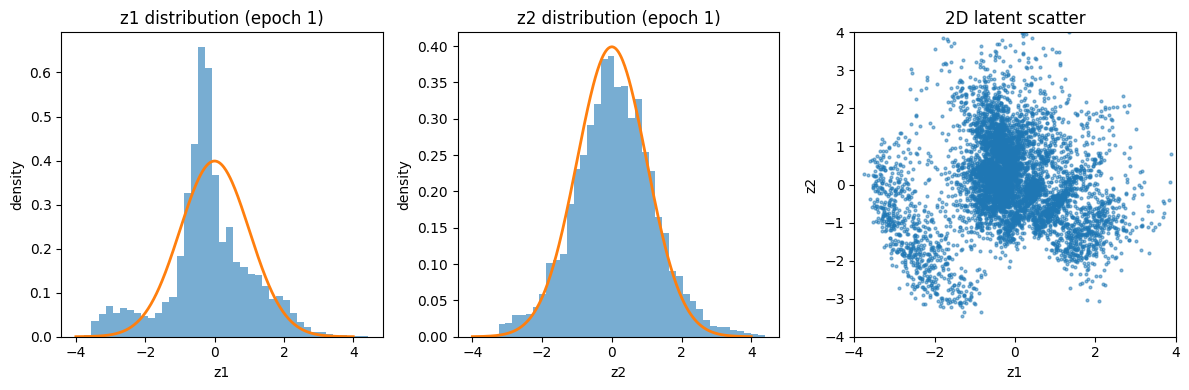

Epoch 02 | Loss 153.0475 | Recon 147.1462 | KL 5.9013
[Test] Loss 153.7356 | Recon 147.9229 | KL 5.8127
[Epoch 2] z1 mean=-0.163, std=1.197 | z2 mean=0.108, std=1.132


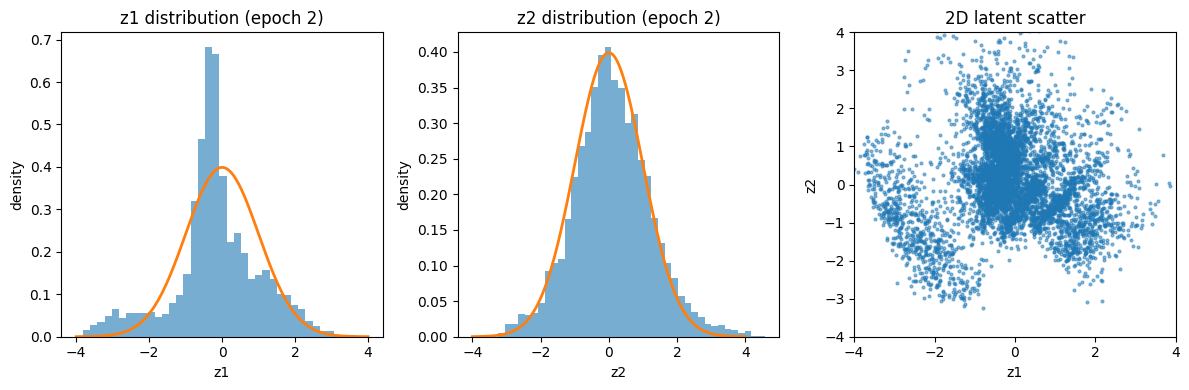

Epoch 03 | Loss 152.6168 | Recon 146.6700 | KL 5.9468
[Test] Loss 153.3399 | Recon 147.2371 | KL 6.1028
[Epoch 3] z1 mean=-0.225, std=1.230 | z2 mean=0.080, std=1.134


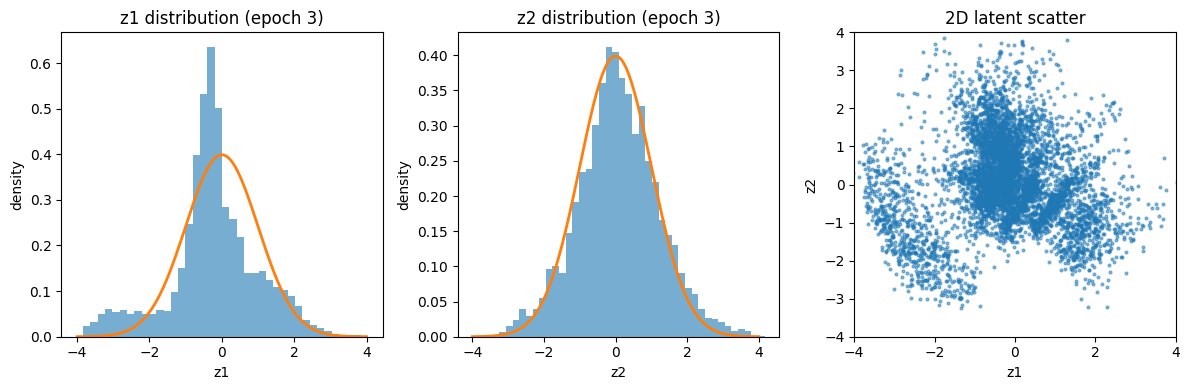

Epoch 04 | Loss 152.1251 | Recon 146.1526 | KL 5.9725
[Test] Loss 152.8625 | Recon 146.9253 | KL 5.9372
[Epoch 4] z1 mean=-0.206, std=1.194 | z2 mean=0.049, std=1.111


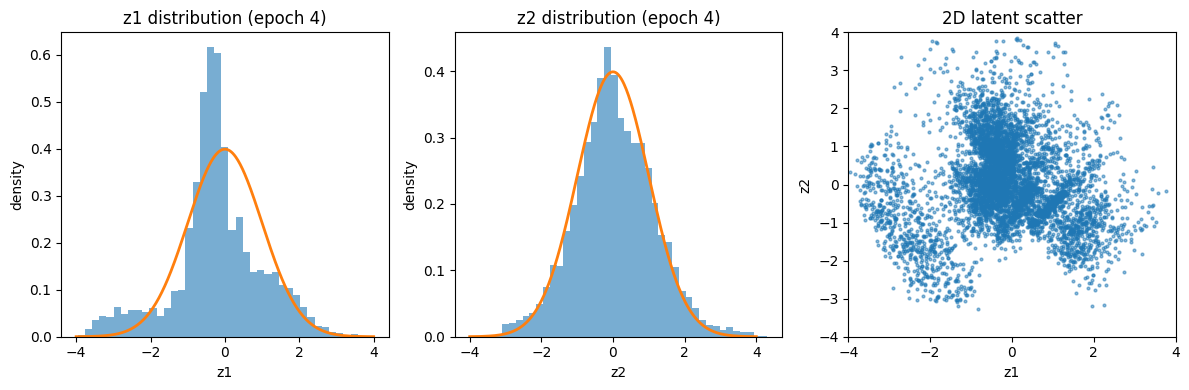

Epoch 05 | Loss 151.7120 | Recon 145.7014 | KL 6.0106
[Test] Loss 152.7966 | Recon 146.7060 | KL 6.0905
[Epoch 5] z1 mean=-0.176, std=1.252 | z2 mean=0.070, std=1.150


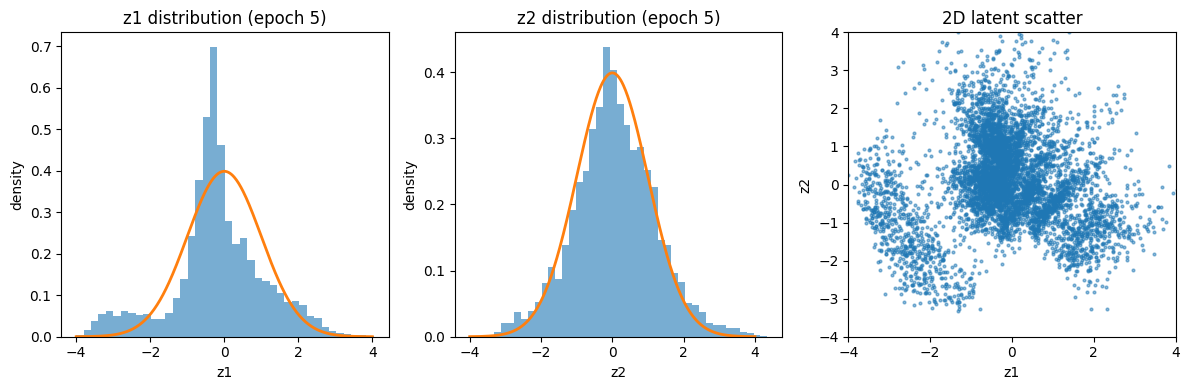

Epoch 06 | Loss 151.3683 | Recon 145.3472 | KL 6.0211
[Test] Loss 152.8980 | Recon 146.6443 | KL 6.2537
[Epoch 6] z1 mean=-0.246, std=1.226 | z2 mean=0.015, std=1.134


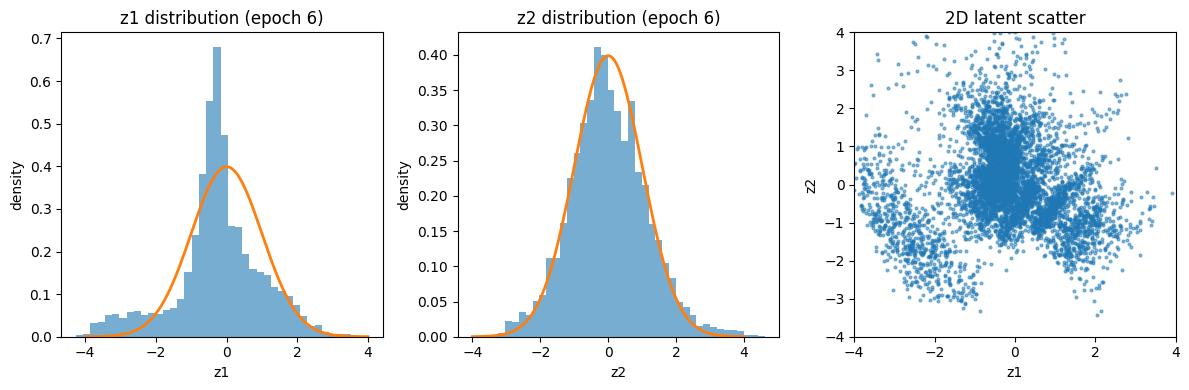

Epoch 07 | Loss 151.0151 | Recon 144.9497 | KL 6.0654
[Test] Loss 152.4030 | Recon 146.4370 | KL 5.9660
[Epoch 7] z1 mean=-0.241, std=1.193 | z2 mean=0.024, std=1.118


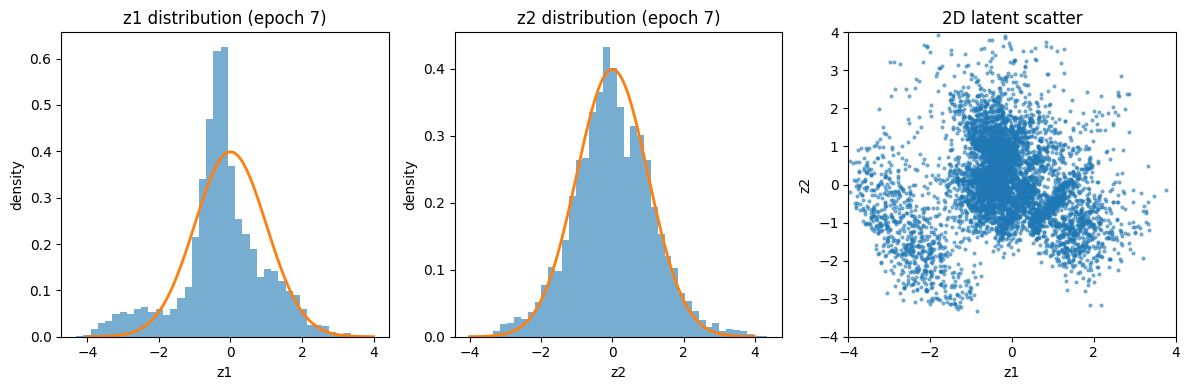

In [ ]:
# train + moniter latent gaussianity per epoch
latent_stats = {
    "epoch": [],
    "mean_z1": [],
    "std_z1": [],
    "mean_z2": [],
    "std_z2": [],
}

num_epochs = 7  # e.g., increase if you want
num_batches_for_latent = 50  # fewer for speed, more for accuracy

for epoch in range(1, num_epochs + 1):
    train_epoch(epoch)
    test_epoch()

    # collect latent samples from test set (you can switch to train_loader)
    z_samples = collect_latent_samples(model, test_loader,
                                       num_batches=num_batches_for_latent,
                                       use_mu=True)  # or False for sampled z

    if z_samples is not None:
        z1 = z_samples[:, 0]
        z2 = z_samples[:, 1]
        m1, s1 = np.mean(z1), np.std(z1)
        m2, s2 = np.mean(z2), np.std(z2)

        latent_stats["epoch"].append(epoch)
        latent_stats["mean_z1"].append(m1)
        latent_stats["std_z1"].append(s1)
        latent_stats["mean_z2"].append(m2)
        latent_stats["std_z2"].append(s2)

        # Visual inspection each epoch
        plot_latent_hist(z_samples, epoch)
